# Lab 6: FEM 1D

### Exercise 1: Use FEM 1D to solve the EDO

Use FEM to solve the next EDO (improve the code seen in class). Compare with the analytical solution for some N elements.

\begin{equation}
-\dfrac{d^2y}{dx^2}=xe^x\,,\text{with}\; y(0)=(3-e)  \;, y(1)=0
\end{equation}


* Build a general scrip to solve a PDE of order two with Dirichlet's conditions: $y(a), y(b), x\,\epsilon\, [a,b]$. Use the method seen in class.

Nota: Solving the Green's function for this particular case we are able to find the analytical solution:
\begin{equation}
y(x) = 1-e-e^x(x-2)-x
\end{equation}

---

### Formulación Débil (Método de Galerkin)

Multiplicamos la ecuación diferencial por una función de prueba $v(x) \in H_0^1(0,1)$ tal que $v(0) = v(1) = 0$ e integramos en el dominio $[0,1]$:

$$-\int_0^1 \frac{d^2y}{dx^2} v(x) \, dx = \int_0^1 x e^x v(x) \, dx$$

Aplicando integración por partes al término de la izquierda:

$$\left[ -\frac{dy}{dx} v(x) \right]_0^1 + \int_0^1 \frac{dy}{dx} \frac{dv}{dx} \, dx = \int_0^1 x e^x v(x) \, dx$$

Dado que $v(0) = v(1) = 0$, el término de frontera se anula. Obtenemos la **forma débil**:

$$\int_0^1 \frac{dy}{dx} \frac{dv}{dx} \, dx = \int_0^1 x e^x v(x) \, dx$$



### Discretización y Funciones de Forma

Dividimos el dominio $[0, 1]$ en $N$ elementos $e = [x_e, x_{e+1}]$ de paso uniforme $h = \frac{1}{N}$.

En cada elemento, la variable $y(x)$ se aproxima linealmente mediante las funciones de forma nodales:

$$N_1^e(x) = \frac{x_{e+1} - x}{h}, \quad N_2^e(x) = \frac{x - x_e}{h}$$

cuyas derivadas respecto a $x$ son:

$$\frac{d N_1^e}{dx} = -\frac{1}{h}, \quad \frac{d N_2^e}{dx} = \frac{1}{h}$$


### Matriz de Rigidez Local ($K^e$) y Vector de Carga Elemental ($F^e$)

### Matriz de Rigidez Local

$$K_{ij}^e = \int_{x_e}^{x_{e+1}} \frac{d N_i^e}{dx} \frac{d N_j^e}{dx} \, dx$$

Sustituyendo las derivadas:

$$K^e = \int_{x_e}^{x_{e+1}} \begin{bmatrix} \left(-\frac{1}{h}\right)^2 & \left(-\frac{1}{h}\right)\left(\frac{1}{h}\right) \\ \left(\frac{1}{h}\right)\left(-\frac{1}{h}\right) & \left(\frac{1}{h}\right)^2 \end{bmatrix} dx = \frac{1}{h} \begin{bmatrix} 1 & -1 \\ -1 & 1 \end{bmatrix}$$

### Vector de Carga Elemental ($F^e$) con Cuadratura de Gauss ($n=3$)

$$F_i^e = \int_{x_e}^{x_{e+1}} x e^x N_i^e(x) \, dx$$

Mapeamos el intervalo $x \in [x_e, x_{e+1}]$ al dominio maestro $\xi \in [-1, 1]$ mediante la transformación:

$$x(\xi) = \frac{x_e + x_{e+1}}{2} + \xi \frac{h}{2}, \quad dx = \frac{h}{2} d\xi$$

Las funciones de forma locales en el elemento maestro son $\phi_1(\xi) = \frac{1-\xi}{2}$ y $\phi_2(\xi) = \frac{1+\xi}{2}$. Aplicando la regla de Gauss de 3 puntos:

$$F_i^e = \frac{h}{2} \sum_{k=1}^3 w_k \cdot f\left(x(\xi_k)\right) \cdot \phi_i(\xi_k)$$

| $k$ | Punto de Gauss ($\xi_k$) | Peso ($w_k$) |
| :---: | :---: | :---: |
| $1$ | $-\sqrt{3/5} \approx -0.7745966$ | $5/9 \approx 0.5555556$ |
| $2$ | $0.0$ | $8/9 \approx 0.8888889$ |
| $3$ | $\sqrt{3/5} \approx 0.7745966$ | $5/9 \approx 0.5555556$ |


### Ensamblaje Global y Condiciones de Frontera

Para la malla global de $N+1$ nodos:
- Para cada nodo interno $i \in \{1, \dots, N-1\}$, la diagonal de la matriz global es $K_{i,i} = \frac{2}{h}$, y las sub/super-diagonales valen $K_{i,i-1} = K_{i,i+1} = -\frac{1}{h}$.
- Modificamos el vector de carga global para incorporar las condiciones de Dirichlet conocidas ($y_0 = 3 - e$ y $y_N = 0$):

$$F_1^{\text{mod}} = F_1 - K_{1,0} \, y_0 = F_1 + \frac{3-e}{h}$$

$$F_{N-1}^{\text{mod}} = F_{N-1} - K_{N-1,N} \, y_N = F_{N-1}$$

El sistema se reduce a dimensión $(N-1) \times (N-1)$ para las incógnitas internas $[y_1, y_2, \dots, y_{N-1}]^T$.

### Solución Analítica mediante Función de Green

Buscamos la función $G(x,s)$ que cumpla:
$$-\frac{\partial^2 G}{\partial x^2} = \delta(x-s), \quad \text{con } G(0,s) = G(1,s) = 0$$

Dado que es una función lineal a tramos a cada lado de $s$:
$$G(x,s) = \begin{cases} \alpha x, & x \le s \\ \beta (1-x), & x \ge s \end{cases}$$

Por continuidad en $x=s$ ($\alpha s = \beta(1-s)$) y el salto en la primera derivada ($\alpha + \beta = 1$), obtenemos $\alpha = 1-s$ y $\beta = s$:
$$G(x,s) = \begin{cases} x(1-s), & x \le s \\ s(1-x), & x \ge s \end{cases}$$

**Solución General:**
Añadimos la solución de la ecuación homogénea $(1-x)y_a + x y_b$ para ajustar las condiciones de frontera:
$$y(x) = (1-x)\int_0^x s f(s) \, ds + x\int_x^1 (1-s) f(s) \, ds + (1-x)y_a + x y_b$$

Sustituyendo $f(s) = s e^s$, $y_a = 3-e$ y $y_b = 0$, obtenemos la solución analítica final:
$$y(x) = 1 - e - e^x(x-2) - x$$

In [1]:
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.integrate as integrate


def fem_1d(N, f, xa, xb, ya, yb, source="gauss"):
    h = (xb - xa) / N
    x = np.zeros(N + 1)
    for i in range(N + 1):
        x[i] = xa + i * h

    t_g = [-math.sqrt(3.0 / 5.0), 0.0, math.sqrt(3.0 / 5.0)]
    w_g = [5.0 / 9.0, 8.0 / 9.0, 5.0 / 9.0]
    diag = np.zeros(N + 1)
    off_diag = np.zeros(N + 1)
    a = np.zeros(N + 1)

    for e in range(N):
        diag[e] += 1.0 / h
        diag[e + 1] += 1.0 / h
        off_diag[e + 1] = -1.0 / h

        if source == "gauss":
            center = 0.5 * (x[e] + x[e + 1])
            for k in range(3):
                fk = f(center + 0.5 * h * t_g[k])
                a[e] += 0.5 * h * w_g[k] * fk * (1.0 - t_g[k]) / 2.0
                a[e + 1] += 0.5 * h * w_g[k] * fk * (1.0 + t_g[k]) / 2.0
        else:
            f_e = f(x[e])
            f_next = f(x[e + 1])
            a[e] += h * (2.0 * f_e + f_next) / 6.0
            a[e + 1] += h * (f_e + 2.0 * f_next) / 6.0

    a[1] -= off_diag[1] * ya
    a[N - 1] -= off_diag[N] * yb

    c = np.zeros(N + 1)
    g = np.zeros(N + 1)
    for i in range(1, N):
        pivot = diag[i] - off_diag[i] * c[i - 1]
        if i < N - 1:
            c[i] = off_diag[i + 1] / pivot
        g[i] = (a[i] - off_diag[i] * g[i - 1]) / pivot

    y = np.zeros(N + 1)
    y[0] = ya
    y[N] = yb
    y[N - 1] = g[N - 1]
    for i in range(N - 2, 0, -1):
        y[i] = g[i] - c[i] * y[i + 1]

    return x, y


def evaluate(x_nodes, y_nodes, x):
    N = len(x_nodes) - 1
    h = x_nodes[1] - x_nodes[0]
    e = int((x - x_nodes[0]) / h)
    if e > N - 1:
        e = N - 1
    phi_e = (x_nodes[e + 1] - x) / h
    phi_next = (x - x_nodes[e]) / h
    return y_nodes[e] * phi_e + y_nodes[e + 1] * phi_next

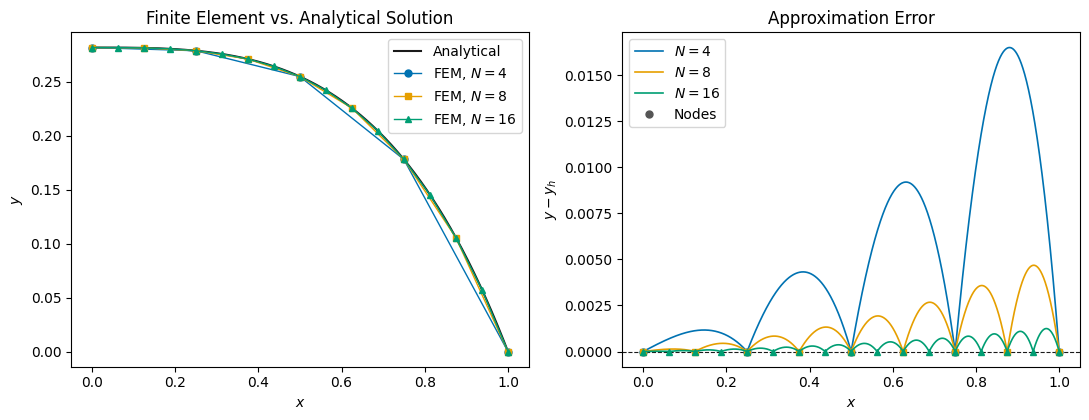

In [2]:
def f(x):
    return x * math.exp(x)


def y_exact(x):
    return 1.0 - math.e - math.exp(x) * (x - 2.0) - x


ya = 3.0 - math.e
yb = 0.0

num_p = 4001
fgrid = np.zeros(num_p)
exf = np.zeros(num_p)
for k in range(num_p):
    fgrid[k] = k / (num_p - 1)
    exf[k] = y_exact(fgrid[k])



colors = {4: "#0072B2", 8: "#E69F00", 16: "#009E73"}
markers = {4: "o", 8: "s", 16: "^"}
n_values = (4, 8, 16)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.0, 4.3))

# Finite Element vs Analytical Solution
ax1.plot(fgrid, exf, color="#1A1A1A", linewidth=1.5, label="Analytical")
for N in n_values:
    x, y = fem_1d(N, f, 0.0, 1.0, ya, yb)
    ax1.plot(x, y, color=colors[N], marker=markers[N], markersize=5, linewidth=1.0, label=f"FEM, $N={N}$")
ax1.set_xlabel("$x$")
ax1.set_ylabel("$y$")
ax1.set_title("Finite Element vs. Analytical Solution")
ax1.legend()

# Error of Approximation
ax2.axhline(0.0, color="#1A1A1A", linewidth=0.8, linestyle="--")
for N in n_values:
    x, y = fem_1d(N, f, 0.0, 1.0, ya, yb)
    error = np.zeros(num_p)
    for k in range(num_p):
        error[k] = exf[k] - evaluate(x, y, fgrid[k])
    node_error = np.zeros(N + 1)
    for i in range(N + 1):
        node_error[i] = y_exact(x[i]) - y[i]
    ax2.plot(fgrid, error, color=colors[N], linewidth=1.2, label=f"$N={N}$")
    ax2.plot(x, node_error, color=colors[N], marker=markers[N], markersize=5, linestyle="none")

ax2.plot([], [], color="#555555", marker="o", markersize=5, linestyle="none", label="Nodes")
ax2.set_xlabel("$x$")
ax2.set_ylabel(r"$y - y_h$")
ax2.set_title("Approximation Error")
ax2.legend()
fig.tight_layout()
plt.show()

In [3]:
n_valores = (4, 8, 16, 32, 64)
datos_tabla = []
error_previo = None

for N in n_valores:
    h = 1.0 / N
    x, y = fem_1d(N, f, 0.0, 1.0, ya, yb)

    y_exacta_nodos = np.array([y_exact(xi) for xi in x])
    err_nodos = np.max(np.abs(y - y_exacta_nodos))
    y_aprox_fina = np.array([evaluate(x, y, x_val) for x_val in fgrid])
    err_max = np.max(np.abs(exf - y_aprox_fina))
    ratio = error_previo / err_max if error_previo is not None else np.nan
    error_previo = err_max

    datos_tabla.append(
        {"N": N, "h": h, "Error Nodos": err_nodos, "Error Máximo": err_max, "Ratio": ratio,})

tabla = pd.DataFrame(datos_tabla)
formato_exp = "{:.2e}".format
formato_float = "{:.5f}".format
formato_ratio = "{:.2f}".format

print(tabla.to_string(index=False,formatters={"h": formato_float, "Error Nodos": formato_exp, "Error Máximo": formato_exp, "Ratio": lambda x: (
                formato_ratio(x) if not np.isnan(x) else "-"), },))

 N       h Error Nodos Error Máximo Ratio
 4 0.25000    8.30e-10     1.65e-02   NaN
 8 0.12500    1.30e-11     4.68e-03  3.52
16 0.06250    2.05e-13     1.25e-03  3.76
32 0.03125    2.72e-15     3.22e-04  3.88
64 0.01562    2.78e-15     8.17e-05  3.94


Vemos que al duplicar $N$, el error se reduce en un factor que tiende a 4 como corresponde a un error de orden $h^2$.